# 📈 Financial Analytics: Previsão e Validação com DARTS

**Autores:** Paloma Vaissman Uribe & Julio Trecenti  
**Instituição:** Insper, PADS | **Ano:** 2026

<a href="https://colab.research.google.com/github/padsInsper/202634-fa/blob/main/complementar/aula03-previsao-validacao-notebook.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

***

Este notebook acompanha os slides da **Aula 3**: copie e execute as células em ordem.

| Parte | Seções | Conteúdo |
|---|---|---|
| **1: DARTS** | 1-6 | Dados, ADF, eval_model(), historical_forecasts() |
| **2: Métricas** | 7-12 | k-fold vs CV temporal, MAE/RMSE/MAPE/MASE, boas práticas |
| **3: Ecossistema** | 13-16 | StatsForecast, Prophet nativo, MLForecast, NeuralForecast, sktime |

> Colab original: https://colab.research.google.com/drive/1wZXsaNmcZIl1xOqAN1K07hy4tt7KTm02


### ⚙️ Instalação

In [1]:
# Execute primeiro: pode demorar alguns minutos no Colab
import subprocess, sys

for pkg in ['darts', 'prophet', 'statsforecast', 'mlforecast', 'neuralforecast', 'sktime', 'lightgbm','tbats']:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

print("✅ Pacotes instalados!")


✅ Pacotes instalados!


In [2]:
from darts import TimeSeries
from darts.models import (
    ExponentialSmoothing,
    Prophet,
    AutoARIMA,
)
from darts.metrics import mape, mae, rmse, r2_score, rmsle
from statsmodels.tsa.stattools import adfuller

import time, warnings, logging
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
logging.getLogger('prophet').setLevel(logging.WARNING)
logging.getLogger('cmdstanpy').disabled = True

print("✅ Imports OK!")


Importing plotly failed. Interactive plots will not work.
/Users/vaissman/Documents/Insper/financial_analytics_light/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✅ Imports OK!


***
## Seção 1 · Dados: AirPassengers

Período: 1949-01-01 00:00:00 → 1960-12-01 00:00:00
Frequência: MS


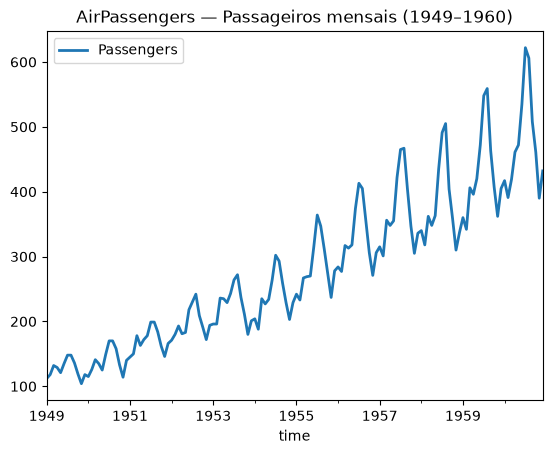

In [3]:
# Dados reais do AirPassengers (hardcoded: sem dependência de URL)
ap_values = [
    112,118,132,129,121,135,148,148,136,119,104,118,
    115,126,141,135,125,149,170,170,158,133,114,140,
    145,150,178,163,172,178,199,199,184,162,146,166,
    171,180,193,181,183,218,230,242,209,191,172,194,
    196,196,236,235,229,243,264,272,237,211,180,201,
    204,188,235,227,234,264,302,293,259,229,203,229,
    242,233,267,269,270,315,364,347,312,274,237,278,
    284,277,317,313,318,374,413,405,355,306,271,306,
    315,301,356,348,355,422,465,467,404,347,305,336,
    340,318,362,348,363,435,491,505,404,359,310,337,
    360,342,406,396,420,472,548,559,463,407,362,405,
    417,391,419,461,472,535,622,606,508,461,390,432,
]
AP = pd.DataFrame({'Passengers': ap_values},
                  index=pd.date_range('1949-01', periods=144, freq='MS'))

# Converter para TimeSeries do DARTS
series = TimeSeries.from_dataframe(AP)

print(f"Período: {series.start_time()} → {series.end_time()}")
print(f"Frequência: {series.freq_str}")
series.plot()
plt.title('AirPassengers: Passageiros mensais (1949-1960)'); plt.show()


In [4]:
# Split treino / val
train, val = series.split_before(pd.Timestamp('19600101'))
print(f"Treino: {len(train)} obs.  ({train.start_time()} → {train.end_time()})")
print(f"Val:    {len(val)}  obs.  ({val.start_time()} → {val.end_time()})")


Treino: 132 obs.  (1949-01-01 00:00:00 → 1959-12-01 00:00:00)
Val:    12  obs.  (1960-01-01 00:00:00 → 1960-12-01 00:00:00)


***
## Seção 2 · Exemplo Rápido: ExponentialSmoothing

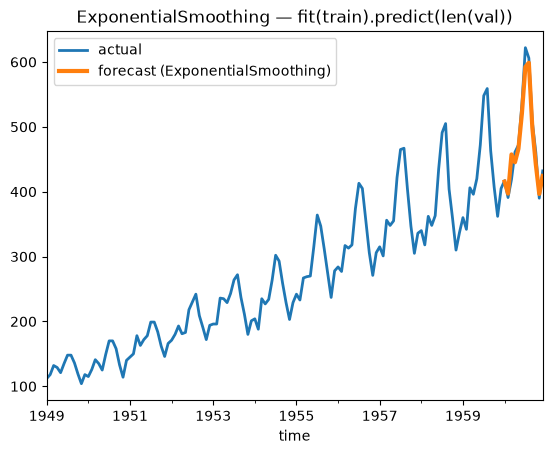

In [5]:
model = ExponentialSmoothing()
model.fit(train)
prediction = model.predict(len(val))

series.plot(label='actual')
prediction.plot(label='forecast (ExponentialSmoothing)', lw=3)
plt.title('ExponentialSmoothing: fit(train).predict(len(val))')
plt.legend(); plt.show()


***
## Seção 3 · Teste de Estacionariedade (ADF)

In [6]:
from statsmodels.tsa.stattools import adfuller

# Converter TimeSeries → DataFrame antes do ADF
result = adfuller(series.to_dataframe())

print(f'ADF Statistic: {result[0]:.4f}')
print(f'p-value:       {result[1]:.4f}')
print(f'Lags usados:   {result[2]}')
print('Critical Values:')
for key, value in result[4].items():
    print(f'\t{key}: {value:.3f}')

if result[1] <= 0.05:
    print("\nRejeita H₀: série ESTACIONÁRIA")
else:
    print("\nNão rejeita H₀: série NÃO ESTACIONÁRIA")

# Output esperado com os dados reais do AirPassengers:
# ADF Statistic:  0.8154
# p-value:        0.9920
# Lags usados:    13
# Critical Values:
#     1%: -3.482
#     5%: -2.884
#    10%: -2.579
# Não rejeita H₀: série NÃO ESTACIONÁRIA


ADF Statistic: 0.8154
p-value:       0.9919
Lags usados:   13
Critical Values:
	1%: -3.482
	5%: -2.884
	10%: -2.579

Não rejeita H₀: série NÃO ESTACIONÁRIA


***
## Seção 4 · Configuração dos Modelos

In [7]:
# ExponentialSmoothing
m_expon = ExponentialSmoothing()

# Prophet multiplicativo: amplitude sazonal cresce com a tendência
m_prophet_m = Prophet(seasonality_mode="multiplicative")

# Prophet aditivo: amplitude sazonal constante
m_prophet_a = Prophet(seasonality_mode="additive")

# AutoARIMA via StatsForecast: rápido e preciso
m_autoarima_stats = AutoARIMA(season_length=12)

# Lista de todos os modelos
models = [m_expon, m_prophet_m, m_prophet_a, m_autoarima_stats]
print(f"✅ {len(models)} modelos configurados:")
for m in models:
    print(f"   • {m}")


✅ 4 modelos configurados:
   • ExponentialSmoothing()
   • Prophet(seasonality_mode=multiplicative)
   • Prophet(seasonality_mode=additive)
   • AutoARIMA(season_length=12)


***
## Seção 5 · Função eval_model()

In [8]:
import time

def eval_model(model, train, val):
    t_start = time.perf_counter()
    print("beginning: " + str(model))

    # Treinar e prever
    res = model.fit(train)
    forecast = model.predict(len(val))

    # Calcular métricas
    res_accuracy = {
        "MAPE":      mape(val, forecast),
        "MAE":       mae(val, forecast),
        "R squared": -r2_score(val, forecast),
        "RMSE":      rmse(val, forecast),
        "RMSLE":     rmsle(val, forecast),
        "time":      time.perf_counter() - t_start,
    }

    print(f"completed: {model} | {res_accuracy['time']:.2f}s")
    return [forecast, res_accuracy, res]


In [9]:
# Testar Prophet multiplicativo
eval_model(m_prophet_m, train, val)[1]


beginning: Prophet(seasonality_mode=multiplicative)
completed: Prophet(seasonality_mode=multiplicative), 0.20s


{'MAPE': np.float64(4.4332454599985125),
 'MAE': np.float64(21.85416058765551),
 'R squared': np.float64(-0.8799867171023334),
 'RMSE': np.float64(25.78391449934088),
 'RMSLE': np.float64(0.05126633868054359),
 'time': 0.19618062500376254}

In [10]:
# Testar AutoARIMA
eval_model(m_autoarima_stats, train, val)[1]


beginning: AutoARIMA(season_length=12)
completed: AutoARIMA(season_length=12), 0.15s


{'MAPE': np.float64(4.1796926177437514),
 'MAE': np.float64(18.515823497791214),
 'R squared': np.float64(-0.8967154852992124),
 'RMSE': np.float64(23.919483693648484),
 'RMSLE': np.float64(0.05350335125515268),
 'time': 0.15428812499158084}

In [11]:
# Rodar todos em sequência
model_predictions = [eval_model(model, train, val) for model in models]


beginning: ExponentialSmoothing()
completed: ExponentialSmoothing(), 0.04s
beginning: Prophet(seasonality_mode=multiplicative)
completed: Prophet(seasonality_mode=multiplicative), 0.04s
beginning: Prophet(seasonality_mode=additive)
completed: Prophet(seasonality_mode=additive), 0.05s
beginning: AutoARIMA(season_length=12)
completed: AutoARIMA(season_length=12), 0.15s


In [12]:
# Montar tabela comparativa df_acc
df_acc = pd.DataFrame.from_dict(model_predictions[0][1], orient="index")
df_acc.columns = [str(models[0])]

for i, m in enumerate(models):
    if i > 0:
        df = pd.DataFrame.from_dict(model_predictions[i][1], orient="index")
        df.columns = [str(m)]
        df_acc = pd.concat([df_acc, df], axis=1)

pd.set_option("display.precision", 3)

# Verde = melhor | Amarelo = pior
df_acc.style     .highlight_min(color="lightgreen", axis=1)     .highlight_max(color="yellow", axis=1)


,ExponentialSmoothing(),Prophet(seasonality_mode=multiplicative),Prophet(seasonality_mode=additive),AutoARIMA(season_length=12)
MAPE,2.803101,4.433245,6.700723,4.179693
MAE,13.381971,21.854161,33.917753,18.515823
R squared,-0.947946,-0.879987,-0.647272,-0.896715
RMSE,16.980953,25.783914,44.203227,23.919484
RMSLE,0.035501,0.051266,0.084047,0.053503
time,0.039822,0.043968,0.046415,0.147504


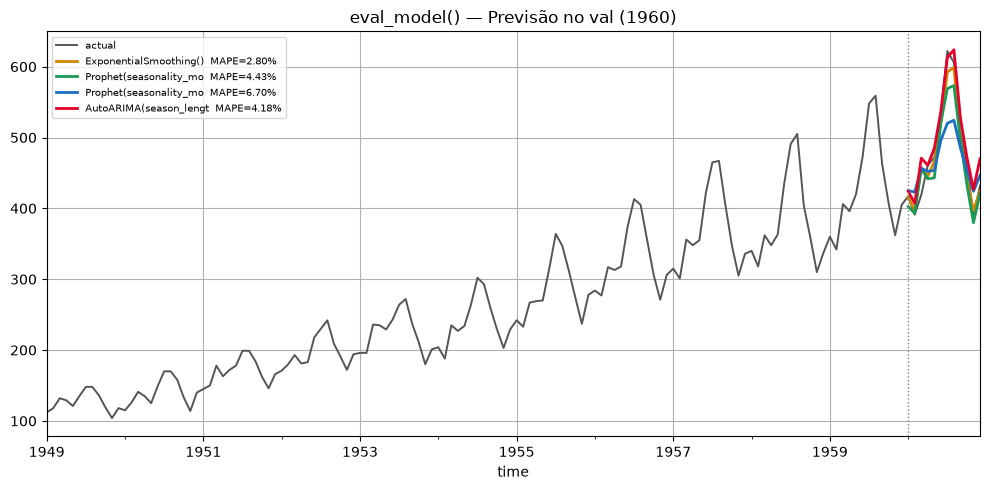

In [13]:
# ── Exportar gráfico df_acc com valores reais ────────────────────────────────
# Execute esta célula APÓS rodar model_predictions
# Gera a3_g3_eval_model.png com os valores reais do seu ambiente

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))
plt.sca(ax)

series.plot(new_plot=False, label='actual', color='#555555', lw=1.4)

cores = ['#cc8800', '#1a9b57', '#1a6fc4', '#E4002B']
for (fc, res, m), cor in zip(model_predictions, cores):
    fc.plot(
        new_plot=False,
        lw=2,
        label=f'{str(m)[:22]}  MAPE={res["MAPE"]:.2f}%',
        color=cor,
    )

ax.axvline(val.start_time(), color='gray', lw=1, ls=':')
ax.set_title('eval_model(): Previsão no val (1960)')
ax.grid(True)
ax.legend(fontsize=7.5)

plt.tight_layout()
plt.savefig('a3_g3_eval_model.png', dpi=130, bbox_inches='tight')
plt.show()

***
## Seção 6 · Backtests com historical_forecasts()

In [14]:
import logging

# Suprimir logs verbosos do Prophet
logging.getLogger("prophet").setLevel(logging.WARNING)
logging.getLogger("cmdstanpy").disabled = True

# Rodar backtests para os 3 modelos principais (incluindo Prophet via DARTS)
models_backtest = [m_expon, m_prophet_m, m_autoarima_stats]

backtests = [
    model.historical_forecasts(
        series,
        start=0.5,             # começa na metade da série
        forecast_horizon=12,   # prevê 12 meses à frente
    )
    for model in models_backtest
]


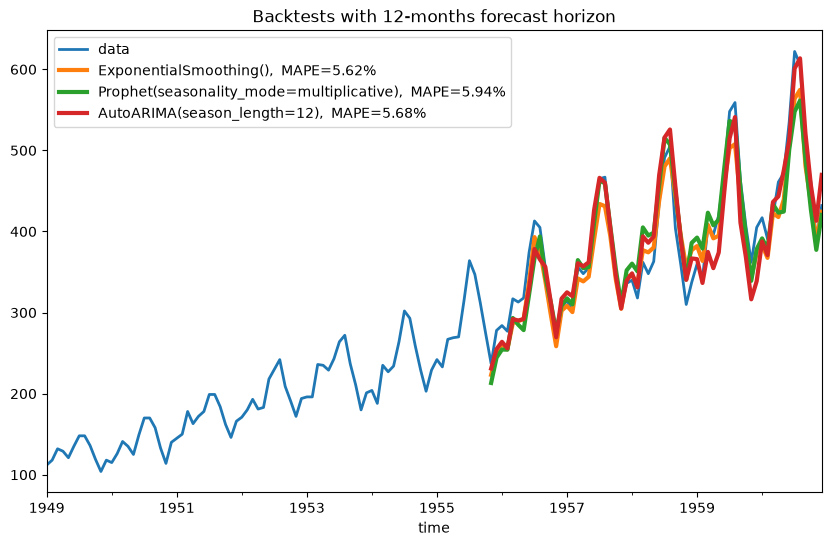

In [15]:
plt.figure(figsize=(10, 6))
series.plot(label='data')
for i, m in enumerate(models_backtest):
    err = mape(backtests[i], series)
    backtests[i].plot(lw=3, label=f'{m},  MAPE={err:.2f}%')

plt.title('Backtests with 12-months forecast horizon')
plt.legend()


In [36]:
backtests

[            Passengers
 1955-11-01     223.216
 1955-12-01     248.155
 1956-01-01     261.787
 1956-02-01     254.694
 1956-03-01     286.885
 ...                ...
 1960-08-01     574.758
 1960-09-01     480.925
 1960-10-01     435.659
 1960-11-01     389.491
 1960-12-01     424.287
 
 shape: (62, 1, 1), freq: MS, size: 496.00 B,
             Passengers
 1955-11-01     213.181
 1955-12-01     244.353
 1956-01-01     254.433
 1956-02-01     254.243
 1956-03-01     293.324
 ...                ...
 1960-08-01     561.496
 1960-09-01     489.156
 1960-10-01     426.986
 1960-11-01     377.368
 1960-12-01     420.426
 
 shape: (62, 1, 1), freq: MS, size: 496.00 B,
             Passengers
 1955-11-01     230.945
 1955-12-01     254.940
 1956-01-01     263.961
 1956-02-01     255.986
 1956-03-01     291.980
 ...                ...
 1960-08-01     613.589
 1960-09-01     521.016
 1960-10-01     457.191
 1960-11-01     413.201
 1960-12-01     469.854
 
 shape: (62, 1, 1), freq: MS, size: 49

***
## Seção 7 · Expanding Window vs Sliding Window

No k-fold convencional o modelo pode treinar com dados futuros (**data leakage**).  
`historical_forecasts()` garante que **treino sempre precede o teste**.


In [16]:
# Expanding (padrão no DARTS)
bt_expanding = m_autoarima_stats.historical_forecasts(
    series, start=0.5, retrain=True
)

# Sliding Window: fixar tamanho de treino
bt_sliding = m_autoarima_stats.historical_forecasts(
    series, start=0.5, retrain=True,
    train_length=60   # janela fixa de 60 observações
)

print(f"Expanding | MAPE: {mape(bt_expanding, series):.2f}%")
print(f"Sliding   | MAPE: {mape(bt_sliding,   series):.2f}%")


Expanding | MAPE: 2.71%
Sliding   | MAPE: 2.84%


## Seção 8 · Métricas de Erro

| Métrica | Fórmula | Quando usar |
|---|---|---|
| **MAE** | $\frac{1}{h}\sum|e_i|$ | Interpretação direta |
| **RMSE** | $\sqrt{\frac{1}{h}\sum e_i^2}$ | Penaliza erros grandes |
| **MAPE** | $\frac{100}{h}\sum|e_i/y_i|$ | Comunicar % |
| **MASE** | MAE / MAE_naïve | Comparar séries diferentes |

> **MASE < 1** → supera o naïve ✓  |  **MASE > 1** → pior que o naïve → descarte o modelo


In [17]:
from darts.metrics import mase, mae, rmse, mape

# Calcular métricas para cada backtest
print(f"{'Modelo':35s}  {'MAPE':>7}  {'MAE':>7}  {'RMSE':>7}")
print('-' * 57)
for bt, m in zip(backtests, models_backtest):
    mape_v = mape(bt, series)
    mae_v  = mae(bt, series)
    rmse_v = rmse(bt, series)
    print(f"{str(m):35s}  {mape_v:7.2f}%  {mae_v:7.1f}  {rmse_v:7.1f}")


Modelo                                  MAPE      MAE     RMSE
---------------------------------------------------------
ExponentialSmoothing()                  5.62%     21.4     25.3
Prophet(seasonality_mode=multiplicative)     5.94%     22.3     27.4
AutoARIMA(season_length=12)             5.68%     21.3     26.2


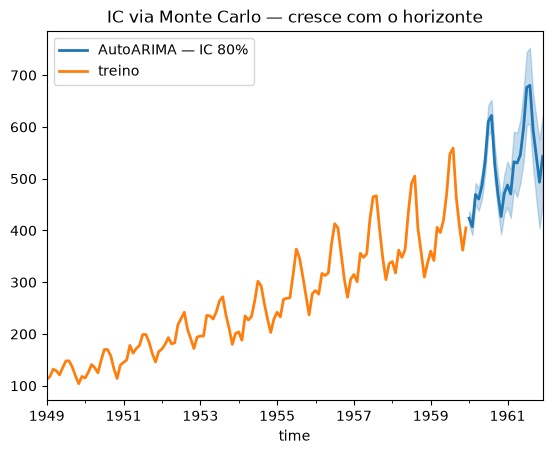

In [18]:
# IC via simulação Monte Carlo (num_samples gera distribuição completa)
prediction = m_autoarima_stats.predict(
    n=24,
    num_samples=500    # 500 trajetórias possíveis
)
prediction.plot(low_quantile=0.1, high_quantile=0.9,
                label='AutoARIMA: IC 80%')
train.plot(label='treino')
plt.title('IC via Monte Carlo: cresce com o horizonte')
plt.legend(); plt.show()


***
## Seção 9 · Outros Modelos no DARTS

In [19]:
from darts.models import (
    TBATS,                    # sazonalidade múltipla complexa
    Theta                   # competidor do Prophet, muito eficiente
)

# A interface é idêntica para qualquer modelo
m_tbats = TBATS(season_length=12)
bt_tbats = m_tbats.historical_forecasts(
    series,
    start=0.5,
    forecast_horizon=12,
)
print(f"TBATS MAPE: {mape(bt_tbats, series):.2f}%")

m_theta = Theta()
bt_theta = m_theta.historical_forecasts(series, start=0.5, forecast_horizon=12)
print(f"Theta MAPE: {mape(bt_theta, series):.2f}%")


TBATS MAPE: 6.61%
Theta MAPE: 8.54%


***
## Seção 10 · StatsForecast: Setup e `cross_validation()`

In [20]:
from statsforecast import StatsForecast
from statsforecast.models import (
    AutoARIMA,      # ARIMA automático: substituto direto do Prophet em muitos casos
    AutoETS,        # Suavização exponencial automática
    AutoTheta,      # Theta automático: competitivo com Prophet
    AutoCES,        # Complex Exponential Smoothing
)

# Preparar dados no formato Nixtla (long format)
df_nixtla = pd.DataFrame({
    'unique_id': 'airline',
    'ds':        AP.index,
    'y':         AP['Passengers'].values
})

# Instanciar com múltiplos modelos
sf = StatsForecast(
    models=[
        AutoARIMA(season_length=12),
        AutoETS(season_length=12),
        AutoTheta(season_length=12),
    ],
    freq='MS',
    n_jobs=-1,
)


In [21]:
# Cross-validation com rolling window
cv_df = sf.cross_validation(
    df=df_nixtla,
    h=12,          # horizonte: 12 meses à frente
    step_size=6,   # novo corte a cada 6 meses
    n_windows=4,   # 4 janelas de avaliação
    refit=True,    # retreina a cada janela (mais realista)
)

print(cv_df.head())
# Colunas: unique_id | ds | cutoff | y | AutoARIMA | AutoETS | AutoTheta
print(f"\nShape: {cv_df.shape}")
print(f"Cutoffs: {cv_df['cutoff'].unique()}")


  unique_id         ds     cutoff      y  AutoARIMA  AutoETS  AutoTheta
0   airline 1958-07-01 1958-06-01  491.0    476.932  452.301    477.505
1   airline 1958-08-01 1958-06-01  505.0    479.160  450.363    475.322
2   airline 1958-09-01 1958-06-01  404.0    416.112  391.600    422.708
3   airline 1958-10-01 1958-06-01  359.0    359.122  342.395    368.962
4   airline 1958-11-01 1958-06-01  310.0    317.120  297.249    322.809

Shape: (48, 7)
Cutoffs: <DatetimeArray>
['1958-06-01 00:00:00', '1958-12-01 00:00:00', '1959-06-01 00:00:00',
 '1959-12-01 00:00:00']
Length: 4, dtype: datetime64[ns]


In [22]:
import numpy as np

# Renomear coluna y para clareza
cv_df = cv_df.rename(columns={'y': 'actual'})

modelos = ['AutoARIMA', 'AutoETS', 'AutoTheta']

print(f"{'Modelo':18s}  {'MAE':>8}  {'RMSE':>8}  {'MAPE':>8}")
print('-' * 52)
for modelo in modelos:
    erros = cv_df['actual'] - cv_df[modelo]
    mae_val  = np.abs(erros).mean()
    rmse_val = np.sqrt((erros**2).mean())
    mape_val = np.abs(erros / cv_df['actual'] * 100).mean()
    print(f"{modelo:18s}  {mae_val:8.1f}  {rmse_val:8.1f}  {mape_val:7.1f}%")


Modelo                   MAE      RMSE      MAPE
----------------------------------------------------
AutoARIMA               25.0      30.4      5.8%
AutoETS                 36.0      42.1      7.8%
AutoTheta               23.9      30.0      5.3%


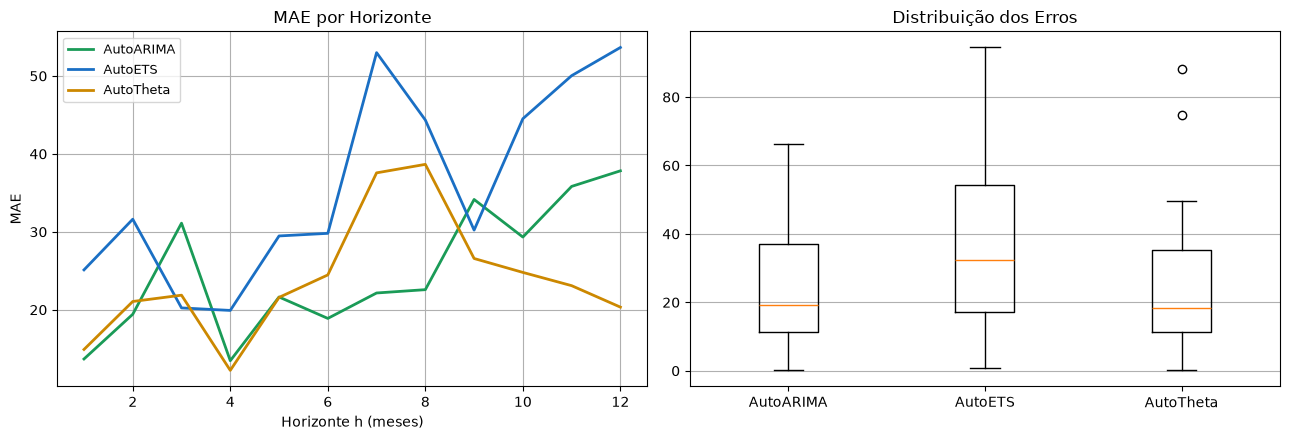

In [23]:
# MAE por horizonte + boxplot de erros
cv_df['horizonte'] = cv_df.groupby(['unique_id', 'cutoff']).cumcount() + 1

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for modelo, cor in zip(modelos, ['#1a9b57', '#1a6fc4', '#cc8800']):
    erro_abs = (cv_df['actual'] - cv_df[modelo]).abs()
    mae_h = erro_abs.groupby(cv_df['horizonte']).mean()
    axes[0].plot(mae_h.index, mae_h.values, lw=2, label=modelo, color=cor)

axes[0].set_title('MAE por Horizonte')
axes[0].set_xlabel('Horizonte h (meses)')
axes[0].set_ylabel('MAE')
axes[0].legend(fontsize=9)
axes[0].grid(True)

erros_dict = {
    modelo: (cv_df['actual'] - cv_df[modelo]).abs().values
    for modelo in modelos
}
axes[1].boxplot(erros_dict.values())
axes[1].set_xticks(range(1, len(erros_dict) + 1))
axes[1].set_xticklabels(erros_dict.keys())
axes[1].set_title('Distribuição dos Erros')
axes[1].grid(True, axis='y')

plt.tight_layout()
plt.show()

In [24]:
# Pipeline completo: StatsForecast para seleção, depois previsão final
sf.fit(df=df_nixtla)

# Inspecionar modelo AutoARIMA selecionado
modelo_arima = sf.fitted_[0, 0].model_
p, q, P, Q, s, d, D = modelo_arima['arma']
print(f"AutoARIMA selecionou: SARIMA({p},{d},{q})({P},{D},{Q})[{s}]")
print(f"AIC: {modelo_arima['aic']:.2f}")

# Previsão final com IC
previsao = sf.predict(h=12, level=[80, 95])
print(previsao)


AutoARIMA selecionou: SARIMA(1,1,0)(0,1,0)[12]
AIC: 1020.39
   unique_id         ds  AutoARIMA  AutoARIMA-lo-95  AutoARIMA-lo-80  \
0    airline 1961-01-01    444.310          421.279          429.251   
1    airline 1961-02-01    418.214          390.228          399.915   
2    airline 1961-03-01    446.243          412.910          424.448   
3    airline 1961-04-01    488.234          450.621          463.641   
4    airline 1961-05-01    499.237          457.695          472.074   
5    airline 1961-06-01    562.236          517.131          532.743   
6    airline 1961-07-01    649.236          600.822          617.580   
7    airline 1961-08-01    633.236          581.728          599.557   
8    airline 1961-09-01    535.236          480.808          499.648   
9    airline 1961-10-01    488.236          431.038          450.836   
10   airline 1961-11-01    417.236          357.395          378.108   
11   airline 1961-12-01    459.236          396.865          418.454   

   

***
## Seção 11 · CV Nativa do Prophet

In [25]:
from prophet import Prophet as ProphetNative
from prophet.diagnostics import cross_validation, performance_metrics
from prophet.plot import plot_cross_validation_metric

# Preparar dados no formato Prophet (ds, y)
df_prophet_train = pd.DataFrame({
    'ds': AP.index[AP.index < pd.Timestamp('1960-01-01')],
    'y':  AP['Passengers'].values[:132]
})

# Ajustar modelo no treino
m = ProphetNative(seasonality_mode='multiplicative')
m.fit(df_prophet_train)

# Cross-validation nativa do Prophet
# initial: treino mínimo | period: espaçamento | horizon: janela avaliada
df_cv = cross_validation(
    m,
    initial='730 days',    # ~2 anos mínimo
    period='180 days',     # novo corte a cada 6 meses
    horizon='365 days',    # avaliar até 1 ano à frente
    parallel='processes'
)

# Métricas por horizonte
df_perf = performance_metrics(df_cv)
print(df_perf[['horizon', 'mae', 'rmse', 'mape']].head(12))


Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.
18:34:35 - cmdstanpy - INFO - Chain [1] start processing
18:34:35 - cmdstanpy - INFO - Chain [1] start processing
18:34:35 - cmdstanpy - INFO - Chain [1] start processing
18:34:35 - cmdstanpy - INFO - Chain [1] start processing
18:34:35 - cmdstanpy - INFO - Chain [1] start processing
18:34:35 - cmdstanpy - INFO - Chain [1] start processing
18:34:35 - cmdstanpy - INFO - Chain [1] start processing
18:34:35 - cmdstanpy - INFO - Chain [1] start processing
18:34:36 - cmdstanpy - INFO - Chain [1] done processing
18:34:36 - cmdstanpy - I

   horizon     mae    rmse   mape
0  37 days  15.098  18.462  0.058
1  41 days  14.843  18.405  0.057
2  42 days  15.513  19.233  0.057
3  46 days  14.523  18.361  0.054
4  48 days  12.316  16.090  0.047
5  52 days  12.412  15.516  0.051
6  53 days  12.768  15.829  0.049
7  54 days  12.670  15.760  0.049
8  57 days  13.765  17.203  0.052
9  58 days  14.057  17.538  0.052
10 59 days  13.382  17.050  0.050
11 62 days  13.849  17.344  0.051


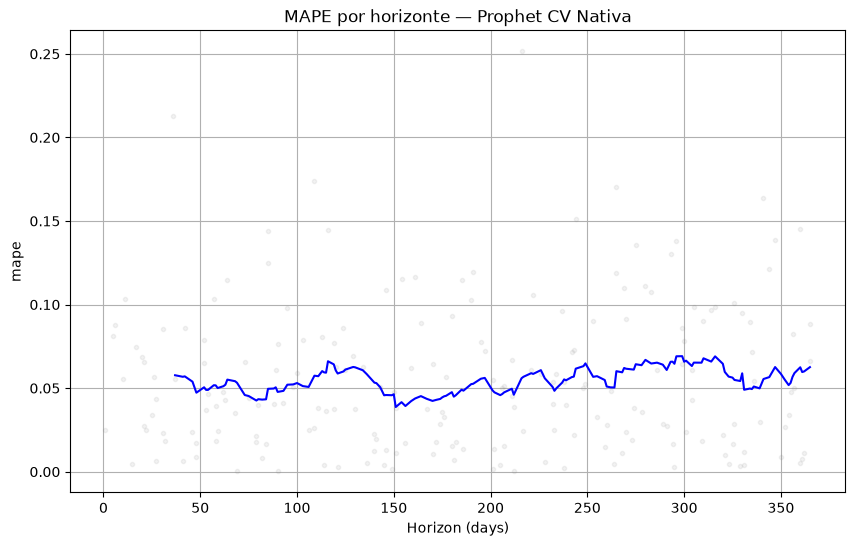


MAE médio Prophet:  15.1
MAPE médio Prophet: 5.5%


In [26]:
# Visualizar MAPE por horizonte
fig = plot_cross_validation_metric(df_cv, metric='mape')
plt.title('MAPE por horizonte: Prophet CV Nativa')
plt.show()

print(f"\nMAE médio Prophet:  {df_perf['mae'].mean():.1f}")
print(f"MAPE médio Prophet: {df_perf['mape'].mean():.1%}")


***
## Seção 12 · MLForecast: ML em Séries Temporais

In [27]:
from mlforecast import MLForecast
from mlforecast.lag_transforms import RollingMean, ExpandingMean
from lightgbm import LGBMRegressor

# Recria df_nixtla apenas se ainda não estiver definido
if 'df_nixtla' not in globals():
    df_nixtla = pd.DataFrame({
        'unique_id': 'airline',
        'ds': AP.index,
        'y': AP['Passengers'].to_numpy(),
    })

# Confere formato e colunas exigidos pelo MLForecast
df_nixtla['ds'] = pd.to_datetime(df_nixtla['ds'])
df_nixtla['y'] = pd.to_numeric(df_nixtla['y'], errors='raise')
df_nixtla = df_nixtla[['unique_id', 'ds', 'y']].sort_values(['unique_id', 'ds'])

fcst = MLForecast(
    models=[LGBMRegressor(), ],
    freq='MS',
    lags=[1, 12],                           # lags 1 mês e 12 meses
    lag_transforms={
        1:  [ExpandingMean()],
        12: [RollingMean(window_size=3)],
    },
    date_features=['month'],                # mês como feature
)

# Cross-validation idêntica ao StatsForecast
cv_ml = fcst.cross_validation(
    df=df_nixtla, h=12, n_windows=4, step_size=6
)

cv_ml = cv_ml.rename(columns={'y': 'actual'})
erros_ml = cv_ml['actual'] - cv_ml['LGBMRegressor']
mae_ml   = np.abs(erros_ml).mean()
mape_ml  = np.abs(erros_ml / cv_ml['actual'] * 100).mean()
print(f"MLForecast (LightGBM) | MAE: {mae_ml:.1f}  MAPE: {mape_ml:.1f}%")


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000236 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 146
[LightGBM] [Info] Number of data points in the train set: 100, number of used features: 5
[LightGBM] [Info] Start training from score 253.420000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -

***
## Seção 13 · sktime: API scikit-learn para Séries

In [34]:
from sktime.forecasting.fbprophet import Prophet as SkProphet
from sktime.forecasting.model_evaluation import evaluate
from sktime.split import ExpandingWindowSplitter

from sktime.performance_metrics.forecasting import (
    MeanAbsoluteError,
    MeanAbsolutePercentageError,
)

cv = ExpandingWindowSplitter(
    initial_window=120,
    step_length=6,
    fh=[1, 6, 12],
)

serie_sk = pd.Series(
    AP["Passengers"].to_numpy(),
    index=pd.PeriodIndex(AP.index, freq="M"),
    name="Passengers",
)

resultados = evaluate(
    forecaster=SkProphet(seasonality_mode="multiplicative"),
    y=serie_sk,
    cv=cv,
    scoring=[
        MeanAbsoluteError(),
        MeanAbsolutePercentageError(),
    ],
)

print(resultados.to_string())

   test_MeanAbsoluteError  test_MeanAbsolutePercentageError  fit_time  pred_time  len_train_window   cutoff
0                  14.533                             0.036     0.056      0.017               120  1958-12
1                  28.775                             0.059     0.030      0.015               126  1959-06
2                  13.462                             0.029     0.026      0.017               132  1959-12


/Users/vaissman/Documents/Insper/financial_analytics_light/.venv/lib/python3.13/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/vaissman/Documents/Insper/financial_analytics_light/.venv/lib/python3.13/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` 

***
## Seção 15 · Comparação Final: Todos os Pacotes

| Situação | Recomendação |
|---|---|
| Explorar a série, comparar modelos intuitivamente | **DARTS** |
| Série com sazonalidade complexa, feriados | **Prophet** (nativo ou via DARTS/sktime) |
| Comparar muitos modelos estatísticos rapidamente | **StatsForecast** |
| Usar LightGBM/XGBoost com lags automáticos | **MLForecast** |
| Deep Learning (N-BEATS, NHITS, TFT) | **NeuralForecast** ou **DARTS** |
| API scikit-learn, pipelines complexos | **sktime** |
| Produção com milhares de séries em paralelo | **StatsForecast** + Spark/Ray |


In [32]:
# Tabela resumo de todos os pacotes
print(f"{'Pacote / Modelo':35s}  {'MAE':>8}  {'MAPE':>8}")
print('=' * 56)

# DARTS backtests
for bt, m in zip(backtests, models_backtest):
    mae_v  = mae(bt, series)
    mape_v = mape(bt, series)
    print(f"{'DARTS | ' + str(m)[:26]:35s}  {mae_v:8.1f}  {mape_v:7.2f}%")

# StatsForecast
for modelo in ['AutoARIMA', 'AutoETS', 'AutoTheta']:
    e = cv_df['actual'] - cv_df[modelo]
    mae_v  = np.abs(e).mean()
    mape_v = np.abs(e / cv_df['actual'] * 100).mean()
    print(f"{'SF | ' + modelo:35s}  {mae_v:8.1f}  {mape_v:7.2f}%")

# Prophet nativo
mae_pn  = df_perf['mae'].mean()
mape_pn = df_perf['mape'].mean() * 100
print(f"{'Prophet nativo | CV':35s}  {mae_pn:8.1f}  {mape_pn:7.2f}%")

# MLForecast
print(f"{'MLForecast | LightGBM':35s}  {mae_ml:8.1f}  {mape_ml:7.2f}%")


Pacote / Modelo                           MAE      MAPE
DARTS: ExponentialSmoothing()           21.4     5.62%
DARTS: Prophet(seasonality_mode=m       22.3     5.94%
DARTS: AutoARIMA(season_length=12       21.3     5.68%
SF: AutoARIMA                           25.0     5.80%
SF: AutoETS                             36.0     7.83%
SF: AutoTheta                           23.9     5.32%
Prophet nativo: CV                      15.1     5.46%
MLForecast: LightGBM                    47.0     9.88%


***
## 🏋️ Exercício Proposto

1. Instale: `pip install darts statsforecast prophet`
2. Carregue o **IBC-Br ou Desemprego** via API BCB
3. Rode o `adfuller`: a série é estacionária?
4. **DARTS:** rode `historical_forecasts(start=0.5, forecast_horizon=12)` com ExponSmoothing, Prophet e AutoARIMA
5. **Prophet nativo:** rode `cross_validation(initial='1460 days', period='180 days', horizon='365 days')` e visualize com `plot_cross_validation_metric()`
6. **StatsForecast:** rode `cross_validation(h=12, n_windows=4)` com AutoARIMA, AutoETS e AutoTheta
7. Compare os rankings: Prophet ficou competitivo frente ao AutoARIMA/AutoETS?
8. **Bônus:** meça o tempo de execução de cada abordagem e compare!


In [37]:
import requests

def bcb_serie(codigo, start='2003-01-01'):
    """Carrega série do BCB via API REST: sem dependências extras."""
    di  = pd.Timestamp(start).strftime('%d/%m/%Y')
    url = (f"https://api.bcb.gov.br/dados/serie/bcdata.sgs.{codigo}/dados"
           f"?formato=json&dataInicial={di}")
    resp = requests.get(url, timeout=30)
    resp.raise_for_status()
    df_bcb = pd.DataFrame(resp.json())
    df_bcb['data']  = pd.to_datetime(df_bcb['data'], dayfirst=True)
    df_bcb['valor'] = pd.to_numeric(df_bcb['valor'], errors='coerce')
    return df_bcb.set_index('data').rename(columns={'valor': f'bcb_{codigo}'}).dropna()

# Carregar e converter para TimeSeries
ibc    = bcb_serie(24363)  # IBC-Br mensal
# desemp = bcb_serie(24369)  # Taxa de desemprego mensal

# serie_bcb = TimeSeries.from_dataframe(
#     ibc.rename(columns={'bcb_24363': 'value'}), freq='MS'
# )
# train_bcb, val_bcb = serie_bcb.split_before(
#     pd.Timestamp(serie_bcb.time_index[-12])
# )

print("✅ Função bcb_serie() pronta!")
print("Sugestões:")
print("  bcb_serie(24363)  # IBC-Br")
print("  bcb_serie(24369)  # Taxa de desemprego")
print("  bcb_serie(433)    # IPCA")


✅ Função bcb_serie() pronta!
Sugestões:
  bcb_serie(24363)  # IBC-Br
  bcb_serie(24369)  # Taxa de desemprego
  bcb_serie(433)    # IPCA


<Axes: xlabel='data'>

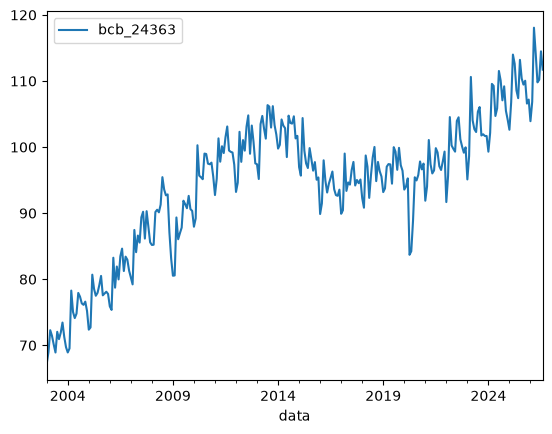

In [39]:
ibc.plot()

In [55]:
from darts.models import (
    AutoETS as DartsAutoETS,
    AutoTheta as DartsAutoTheta,
    AutoARIMA as DartsAutoARIMA,
)

# Preparar a série mensal do IBC-Br
ibc_cv_df = ibc[['bcb_24363']].copy()
ibc_cv_df.index = pd.DatetimeIndex(ibc_cv_df.index).to_period('M').to_timestamp()
ibc_cv_df = ibc_cv_df.sort_index().asfreq('MS')

if ibc_cv_df.isna().any().any():
    raise ValueError("A série do IBC-Br contém meses ausentes; verifique os dados antes do CV.")

ibc_series = TimeSeries.from_dataframe(ibc_cv_df, freq='MS')

# Modelos DARTS: aliases evitam conflito com AutoARIMA do StatsForecast
modelos_ibc = [
    ("AutoETS", DartsAutoETS(season_length=12)),
    ("AutoTheta", DartsAutoTheta(season_length=12)),
    ("AutoARIMA", DartsAutoARIMA(season_length=12)),
    ("Prophet multiplicativo", Prophet(seasonality_mode="multiplicative")),
    ("Prophet aditivo", Prophet(seasonality_mode="additive")),
    ("TBATS", TBATS(season_length=12)),
]

resultados_ibc = []

for nome, modelo in modelos_ibc:
    print(f"Executando CV: {nome}")

    try:
        previsoes_cv = modelo.historical_forecasts(
            ibc_series,
            start=0.5,
            forecast_horizon=12,
            stride=3,
            retrain=True,
            last_points_only=False,
            verbose=False,
        )

        y_real, y_previsto = [], []

        for previsao_cv in previsoes_cv:
            pred = previsao_cv.to_dataframe().iloc[:, 0]
            real = ibc_series.to_dataframe().iloc[:, 0].reindex(pred.index)
            validos = real.notna() & pred.notna()

            y_real.extend(real[validos].to_numpy())
            y_previsto.extend(pred[validos].to_numpy())

        y_real = np.asarray(y_real, dtype=float)
        y_previsto = np.asarray(y_previsto, dtype=float)

        resultados_ibc.append({
            "Modelo": nome,
            "Janelas": len(previsoes_cv),
            "Observações avaliadas": len(y_real),
            "MAE": np.mean(np.abs(y_real - y_previsto)),
            "RMSE": np.sqrt(np.mean((y_real - y_previsto) ** 2)),
            "MAPE (%)": np.mean(np.abs((y_real - y_previsto) / y_real)) * 100,
        })

    except Exception as erro:
        print(f"Falha em {nome}: {erro}")

df_cv_ibc = pd.DataFrame(resultados_ibc).set_index("Modelo")
display(df_cv_ibc.sort_values("MAE"))

Executando CV: AutoETS
Executando CV: AutoTheta
Executando CV: AutoARIMA
Executando CV: Prophet multiplicativo
Executando CV: Prophet aditivo
Executando CV: TBATS


,Janelas,Observações avaliadas,MAE,RMSE,MAPE (%)
Modelo,,,,,
TBATS,44,528,2.501,3.518,2.559
AutoARIMA,44,528,2.509,3.691,2.569
AutoTheta,44,528,2.582,3.635,2.652
AutoETS,44,528,2.648,3.621,2.692
Prophet multiplicativo,44,528,3.745,4.479,3.835
Prophet aditivo,44,528,3.762,4.488,3.849


In [ ]:
backtests_ibc_plot = {}

for nome, modelo in modelos_ibc:
    print(f"Executando backtest: {nome}")
    backtests_ibc_plot[nome] = modelo.historical_forecasts(
        ibc_series,
        start=0.5,
        forecast_horizon=12,
        stride=3,
        retrain=True,
        last_points_only=False,
        verbose=False,
    )

fig, axes = plt.subplots(3, 2, figsize=(15, 12), sharex=True)
axes = axes.ravel()

historico = ibc_series.to_dataframe().iloc[:, 0]

for ax, (nome, previsoes) in zip(axes, backtests_ibc_plot.items()):
    # Junta as previsões das diferentes janelas, alinhadas por data
    previsoes_df = pd.concat(
        [fc.to_dataframe().iloc[:, 0] for fc in previsoes],
        axis=1,
    )

    media = previsoes_df.mean(axis=1)
    p10 = previsoes_df.quantile(0.10, axis=1)
    p90 = previsoes_df.quantile(0.90, axis=1)

    ax.plot(historico.index, historico, color="black", lw=1.5, label="IBC-Br real")
    ax.plot(media.index, media, lw=2, label="Previsão média")
    ax.fill_between(media.index, p10, p90, alpha=0.2, label="P10-P90")

    ax.set_title(nome)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

for ax in axes[len(backtests_ibc_plot):]:
    ax.set_visible(False)

fig.suptitle("Backtests do IBC-Br: comparação entre modelos", fontsize=15)
plt.tight_layout()
plt.show()

,bcb_24363
data,
2026-09-01,110.652
2026-10-01,111.353
2026-11-01,109.041
2026-12-01,109.764
2027-01-01,106.057
2027-02-01,108.089
2027-03-01,116.968
2027-04-01,113.195
2027-05-01,110.816


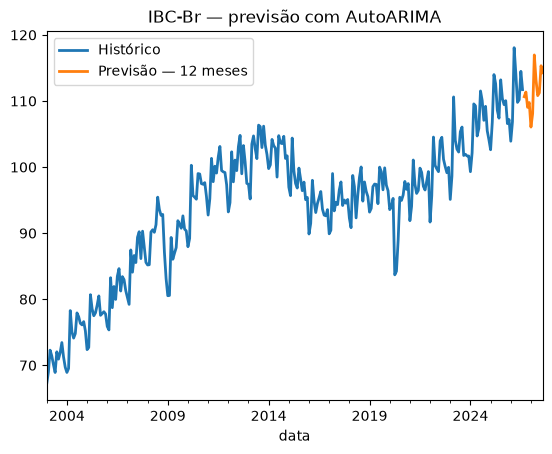

In [57]:
modelo_autoarima_final = DartsAutoARIMA(season_length=12)
modelo_autoarima_final.fit(ibc_series)

previsao_6 = modelo_autoarima_final.predict(n=12)

display(previsao_6.to_dataframe())

ibc_series.plot(label='Histórico')
previsao_6.plot(new_plot=False, label='Previsão: 12 meses', lw=2)
plt.title('IBC-Br: previsão com AutoARIMA')
plt.legend()
plt.show()

,bcb_24363
data,
2026-09-01,109.534
2026-10-01,111.222
2026-11-01,109.163
2026-12-01,108.794
2027-01-01,105.395
2027-02-01,106.698
2027-03-01,113.694
2027-04-01,111.009
2027-05-01,109.639


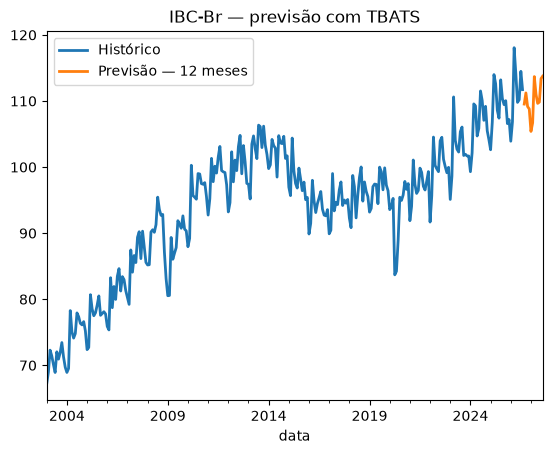

In [58]:
modelo_tbats_final = TBATS(season_length=12)
modelo_tbats_final.fit(ibc_series)

previsao_7 = modelo_tbats_final.predict(n=12)

display(previsao_7.to_dataframe())

ibc_series.plot(label='Histórico')
previsao_7.plot(new_plot=False, label='Previsão: 12 meses', lw=2)
plt.title('IBC-Br: previsão com TBATS')
plt.legend()
plt.show()

***
## 📖 Referências

- **DARTS**: [unit8co.github.io/darts](https://unit8co.github.io/darts/)
- **StatsForecast**: [nixtlaverse.nixtla.io/statsforecast](https://nixtlaverse.nixtla.io/statsforecast/)
- **Prophet**: [facebook.github.io/prophet/docs/diagnostics.html](https://facebook.github.io/prophet/docs/diagnostics.html)
- **MLForecast**: [nixtlaverse.nixtla.io/mlforecast](https://nixtlaverse.nixtla.io/mlforecast/)
- **NeuralForecast**: [nixtlaverse.nixtla.io/neuralforecast](https://nixtlaverse.nixtla.io/neuralforecast/)
- **sktime** | [sktime.net](https://www.sktime.net/)
- **Colab da aula**: [colab.research.google.com/drive/1wZXsaNmcZIl1xOqAN1K07hy4tt7KTm02](https://colab.research.google.com/drive/1wZXsaNmcZIl1xOqAN1K07hy4tt7KTm02)
